# Plots and tables: plan for the key results

**Goal:** show the main results of the `facebook/opt-1.3b` benchmark in **one table and two figures**.

**Data**
- `opt13b/`: KGW, MorphMark, PF, SynthID and SIR, plus the unwatermarked and human baselines, with both attacks (this was `dipper_run`).
- `opt13b/sem_stamp_run/`: adds SemStamp (C4 only).

## Recommendation at a glance
- **Table 1: main results (compact).** Quality cost and detection with and without attack, on 6 rows and 4 columns, small enough for the report.
- **Figure 1 (headline): detection before and after attacks.** A dot plot showing that watermarks survive word deletion but mostly not paraphrasing.
- **Figure 2: what robustness costs.** A scatter of quality cost against robustness to paraphrasing.

**Why only two figures**
- Detection without attack is near-perfect for 5 of 6 methods, so a figure about it (e.g. ROC curves) would show little. The table covers it.
- The translation and summarization scores (BLEU, ROUGE-L) differ only slightly between methods, so they belong in the text or an appendix.

Each section below has the reasoning first and a working draft after it.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN = Path("opt13b")
SEMSTAMP_RUN = RUN / "sem_stamp_run"

METHODS = ["KGW", "MorphMark", "PF", "SynthID", "SIR", "SemStamp"]
PLOT_METHODS = [m for m in METHODS if m != "SemStamp"]  # the figures leave SemStamp out
PLOT_NAMES = {"MorphMark": "MM"}  # shorter names used only in the figures
NAMES = {"none": "Unwatermarked", "human": "Human"}

# One row per variant. The SemStamp run repeats the human row, so take only SemStamp from it.
main = pd.read_csv(RUN / "summary.csv")
semstamp = pd.read_csv(SEMSTAMP_RUN / "summary.csv")
semstamp = semstamp[semstamp["variant"] == "SemStamp"]
summary = pd.concat([main, semstamp], ignore_index=True).set_index("variant")

# Paired perplexity change vs. unwatermarked text (same prompts), with 95% bootstrap CIs.
deltas = pd.concat([pd.read_csv(RUN / "paired_deltas.csv"),
                    pd.read_csv(SEMSTAMP_RUN / "paired_deltas.csv")])
is_c4_ppl = (deltas["dataset"] == "c4") & (deltas["metric"] == "log_ppl")
ppl_deltas = deltas[is_c4_ppl].set_index("variant")

summary.loc[METHODS, ["ppl_corpus", "tpr@1%fpr_vs_human", "attacked_tpr_word_deletion", "attacked_tpr_dipper"]]

,ppl_corpus,tpr@1%fpr_vs_human,attacked_tpr_word_deletion,attacked_tpr_dipper
variant,,,,
KGW,26.388662,0.997826,0.973913,0.382609
MorphMark,18.549530,0.997821,0.945534,0.322440
PF,13.877831,1.000000,0.469298,0.096491
SynthID,19.999291,1.000000,0.911255,0.138528
SIR,28.965878,0.979821,0.943946,0.511211
SemStamp,19.053049,0.661972,0.105769,0.093677


### Shared style
The colors come from the same reference palette that `scripts/paper_assets.py` uses, so these drafts match the paper figures.
- **Figure 1** uses shades of one blue, from light (no attack) to dark (strongest attack), plus a different marker shape for each condition, so it also works in grayscale and for colorblind readers.
- **Figure 2** uses a single color with the method names written next to the points. Five differently colored points are hard to tell apart for colorblind readers.
- **SemStamp** is left out of both figures. It still appears in Table 1.

In [2]:
BLUE_LIGHT = "#86b6ef"   # ramp step 250
BLUE = "#2a78d6"         # ramp step 450
BLUE_DARK = "#104281"    # ramp step 650
INK = "#0b0b0b"          # main text
INK2 = "#52514e"         # secondary text
MUTED = "#898781"        # axis labels
GRID = "#e1e0d9"         # hairlines
AXIS = "#c3c2b7"         # baseline
SURFACE = "#ffffff"

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2,
    "xtick.color": MUTED,
    "ytick.color": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Table 1: main results (compact, for the report)

**Message:** what each watermark costs in text quality, and how well it is detected with and without attack.

**Layout:** 6 rows (one per method) and 4 number columns.

| Method | Perplexity change | No attack | Word deletion | DIPPER |
|---|---|---|---|---|
| KGW | +37% | 100% | 97% | 38% |
| ... | | | | |

**What is shown**
- **Perplexity change:** the change in perplexity compared with unwatermarked text from the same prompts (C4). It is the same number as the x-axis of Figure 2, so no reference rows are needed.
- **Detection columns:** TPR at 1% FPR on C4, meaning the share of watermarked texts caught when only 1 in 100 human texts is wrongly flagged. The best value in each column is in bold.
- Every value comes from C4. Nothing is averaged over datasets.

**Left out, for the text or an appendix**
- AUROC, which is about 1.0 for everyone except SemStamp.
- Diversity, BLEU, ROUGE-L and speed, where the differences are small or the setup differs (SemStamp ran on C4 only, in a separate job).
- Mention in the text instead: PF's lower perplexity comes with more repetitive text, and SemStamp is about 4x slower than the others.

**Suggested caption:** *Text quality cost and detection rate (TPR at 1% FPR) on C4, without attack and after word deletion (30% of words) or DIPPER paraphrasing. Perplexity change is relative to unwatermarked text from the same prompts.*

The last cell prints a LaTeX version for the report.

In [3]:
ppl_change_pct = (np.exp(ppl_deltas.loc[METHODS, "delta_vs_none"]) - 1) * 100
t = summary.loc[METHODS]

table = pd.DataFrame({
    ("", "Perplexity change"): ppl_change_pct,
    ("Detected (TPR@1% FPR)", "No attack"): t["tpr@1%fpr_vs_human"] * 100,
    ("Detected (TPR@1% FPR)", "Word deletion"): t["attacked_tpr_word_deletion"] * 100,
    ("Detected (TPR@1% FPR)", "DIPPER"): t["attacked_tpr_dipper"] * 100,
})
table.index.name = None
detection_cols = [c for c in table.columns if c[0] != ""]


def signed_percent(value):
    value = round(value)
    if value == 0:
        return "0%"
    return f"{value:+d}%"


def bold_best(column):
    # Compare the values as displayed (whole percent), so ties after rounding are all bold.
    rounded = column.round(0)
    return ["font-weight: bold" if value == rounded.max() else "" for value in rounded]


table_style = (
    table.style
    .format(signed_percent, subset=[("", "Perplexity change")])
    .format("{:.0f}%", subset=detection_cols)
    .apply(bold_best, subset=detection_cols)
)
table_style

In [4]:
# LaTeX version for the report (needs \usepackage{booktabs}).
latex = table_style.to_latex(hrules=True, convert_css=True, multicol_align="c", column_format="lrrrr")
print(latex.replace("%", "\\%"))

\begin{tabular}{lrrrr}
\toprule
 &  & \multicolumn{3}{c}{Detected (TPR@1\% FPR)} \\
 & Perplexity change & No attack & Word deletion & DIPPER \\
\midrule
KGW & +37\% & \bfseries 100\% & \bfseries 97\% & 38\% \\
MorphMark & -2\% & \bfseries 100\% & 95\% & 32\% \\
PF & -27\% & \bfseries 100\% & 47\% & 10\% \\
SynthID & +5\% & \bfseries 100\% & 91\% & 14\% \\
SIR & +48\% & 98\% & 94\% & \bfseries 51\% \\
SemStamp & 0\% & 66\% & 11\% & 9\% \\
\bottomrule
\end{tabular}



## Figure 1 (headline): detection before and after attacks

**Message:** without an attack, almost every watermark is detected reliably, and most survive word deletion. **DIPPER paraphrasing removes most of them.**

**Form: dot plot.** Each method gets one row with three dots on a 0–100% scale, one per condition: no attack, word deletion, and DIPPER. The gray line between them shows how much detection is lost.
- Rows are sorted by the DIPPER result, so the plot doubles as a ranking.
- Grouped bars would need 18 bars and look much busier. Here everything shares one axis and one unit.

**Possible extension:** 95% confidence intervals for each dot. `scripts/paper_assets.py` computes them in `numbers_robustness.json`.

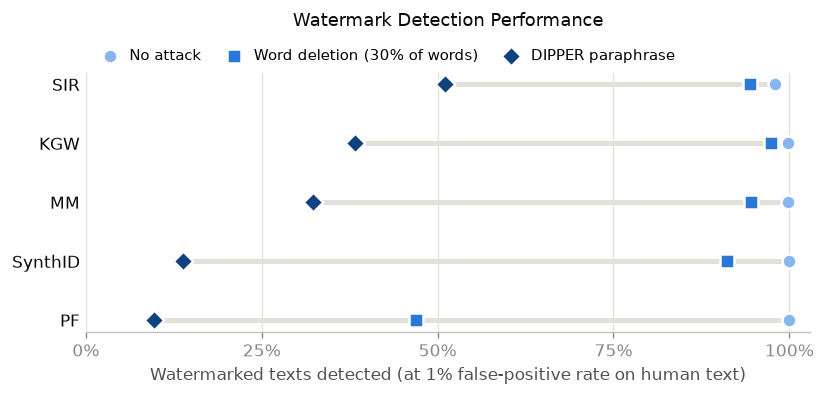

In [5]:
conditions = [
    # (column, legend label, color, marker)
    ("tpr@1%fpr_vs_human", "No attack", BLUE_LIGHT, "o"),
    ("attacked_tpr_word_deletion", "Word deletion (30% of words)", BLUE, "s"),
    ("attacked_tpr_dipper", "DIPPER paraphrase", BLUE_DARK, "D"),
]

# Lowest DIPPER result at the bottom, so the most robust method ends up on top.
order = summary.loc[PLOT_METHODS].sort_values("attacked_tpr_dipper").index
y_positions = np.arange(len(order))

fig, ax = plt.subplots(figsize=(7, 3.4))

# Gray line from each method's lowest to highest value.
for y, method in zip(y_positions, order):
    values = [summary.loc[method, col] * 100 for col, _, _, _ in conditions]
    ax.plot([min(values), max(values)], [y, y], color=GRID, linewidth=3, zorder=1)

for col, label, color, marker in conditions:
    ax.scatter(summary.loc[order, col] * 100, y_positions, s=70, color=color, marker=marker,
               edgecolor=SURFACE, linewidth=1.5, label=label, zorder=3)

ax.set_yticks(y_positions, [PLOT_NAMES.get(m, m) for m in order])
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlim(0, 103)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Watermarked texts detected (at 1% false-positive rate on human text)")

ax.set_title("Watermark Detection Performance",
              fontsize=11, color=INK, pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9,
          handletextpad=0.3, columnspacing=1.2, borderaxespad=0.2)

fig.tight_layout()
# fig.savefig("fig_detection_under_attack.pdf", bbox_inches="tight")
plt.show()

## Figure 2: what robustness costs

**Message:** the methods that survive paraphrasing best, SIR and KGW, also raise perplexity the most. MorphMark is the middle ground: no measurable quality cost, and still 32% detected after DIPPER.

**Form: scatter plot, one point per method.**
- **x-axis:** perplexity change compared with unwatermarked text from the same prompts, in %, with 95% confidence intervals. 0 means no quality cost.
- **y-axis:** share of texts still detected after DIPPER.
- The dashed line at 0 marks "no change in perplexity".

**Points to mention in the caption**
- PF's lower perplexity comes with less diverse, more repetitive text, so it is not a quality gain.

**Alternatives**
- Use the word-deletion result on the y-axis instead.
- Show both attacks as two small side-by-side panels with the same axes.

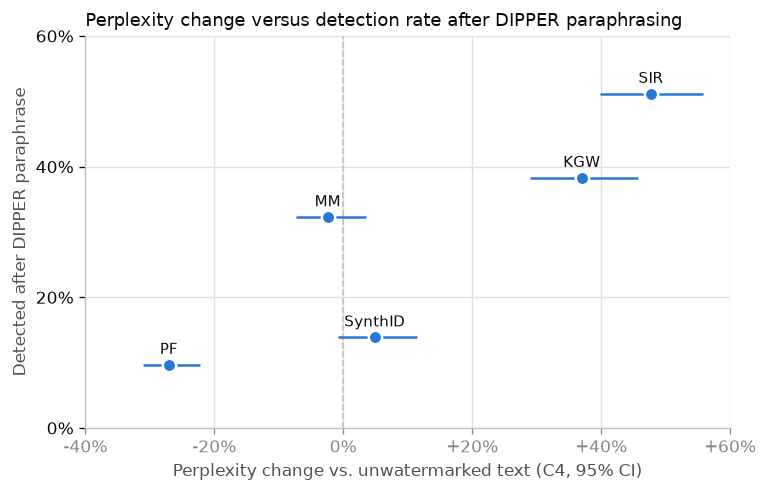

In [6]:
ppl_change = (np.exp(ppl_deltas.loc[PLOT_METHODS, "delta_vs_none"]) - 1) * 100
ppl_low = (np.exp(ppl_deltas.loc[PLOT_METHODS, "ci_low"]) - 1) * 100
ppl_high = (np.exp(ppl_deltas.loc[PLOT_METHODS, "ci_high"]) - 1) * 100
dipper = summary.loc[PLOT_METHODS, "attacked_tpr_dipper"] * 100

# Where each name sits relative to its point (in points), chosen by hand to avoid overlaps.
label_offsets = {
    "KGW": (0, 9), "MorphMark": (0, 9), "PF": (0, 9),
    "SynthID": (0, 9), "SIR": (0, 9),
}

fig, ax = plt.subplots(figsize=(6.5, 4.2))

ax.axvline(0, color=AXIS, linewidth=1, linestyle="--", zorder=1)

ax.errorbar(ppl_change, dipper, xerr=[ppl_change - ppl_low, ppl_high - ppl_change],
            fmt="o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5,
            ecolor=BLUE, elinewidth=1.5, capsize=0, zorder=3)

for method in PLOT_METHODS:
    ax.annotate(PLOT_NAMES.get(method, method), (ppl_change[method], dipper[method]),
                xytext=label_offsets[method],
                textcoords="offset points", ha="center", va="center",
                fontsize=9, color=INK)

ax.set_xlim(-40, 60)
ax.set_ylim(0, 60)
ax.set_xticks([-40, -20, 0, 20, 40, 60], ["-40%", "-20%", "0%", "+20%", "+40%", "+60%"])
ax.set_yticks([0, 20, 40, 60], ["0%", "20%", "40%", "60%"])
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Perplexity change vs. unwatermarked text (C4, 95% CI)")
ax.set_ylabel("Detected after DIPPER paraphrase")
ax.set_title("Perplexity change versus detection rate after DIPPER paraphrasing",
             loc="left", fontsize=11, color=INK)

fig.tight_layout()
# fig.savefig("fig_quality_vs_robustness.pdf", bbox_inches="tight")
plt.show()

## Considered, not recommended
- **ROC curves:** five of six methods sit at near-perfect detection, so the curves overlap and show little. A copy already exists at `opt13b/plots/roc_vs_human.png`.
- **Radar or spider chart:** hard to read, and the enclosed area depends on the order of the axes, which makes it misleading.
- **One bar chart of all metrics:** the metrics have different units, so it would need several y-axes.
- **BLEU and ROUGE-L bars:** the differences are small, so the table is enough.
- **Score histograms:** a technical detail better suited to an appendix. A copy exists at `opt13b/plots/score_histograms.png`.

## Next steps
- Choose the table and figures to keep. They can then be polished: for example, a 3.3 in wide version for one paper column, PDF export, and confidence intervals in Figure 1.
- Optionally, add them to `scripts/paper_assets.py` so they are regenerated together with the other paper assets.

## Qwen2.5-1.5B-Instruct: the same two figures

**Data:** `qwen15b-20261019-173051/`: KGW, MorphMark, PF, SynthID and SIR on `Qwen/Qwen2.5-1.5B-Instruct`, with both attacks. No SemStamp. GSM8K (math word problems) was added as a fourth task.

**Read with care when comparing to OPT-1.3B**
- Perplexity is judged by a different model here (`Qwen2.5-7B-Instruct` instead of `opt-2.7b`), so only the *change* vs. unwatermarked text is comparable, not the raw values.
- Qwen stops writing earlier: detection is scored on about 120 tokens per text instead of about 180. Shorter texts carry a weaker watermark signal.

Both figures use the same style and y-axis as the OPT versions above. Figure 2 needs a wider x-axis, because KGW and SIR raise perplexity more on Qwen.

In [7]:
QWEN_RUN = Path("qwen15b-20261019-173051")

qwen_summary = pd.read_csv(QWEN_RUN / "summary.csv").set_index("variant")

qwen_deltas = pd.read_csv(QWEN_RUN / "paired_deltas.csv")
is_c4_ppl = (qwen_deltas["dataset"] == "c4") & (qwen_deltas["metric"] == "log_ppl")
qwen_ppl_deltas = qwen_deltas[is_c4_ppl].set_index("variant")

qwen_summary.loc[PLOT_METHODS, ["ppl_corpus", "tpr@1%fpr_vs_human", "attacked_tpr_word_deletion", "attacked_tpr_dipper"]]

,ppl_corpus,tpr@1%fpr_vs_human,attacked_tpr_word_deletion,attacked_tpr_dipper
variant,,,,
KGW,33.742927,0.981265,0.740047,0.229508
MorphMark,18.884192,0.887588,0.512881,0.147541
PF,14.902884,1.000000,0.180751,0.063529
SynthID,18.828223,1.000000,0.582524,0.140436
SIR,34.744952,0.795238,0.761905,0.161905


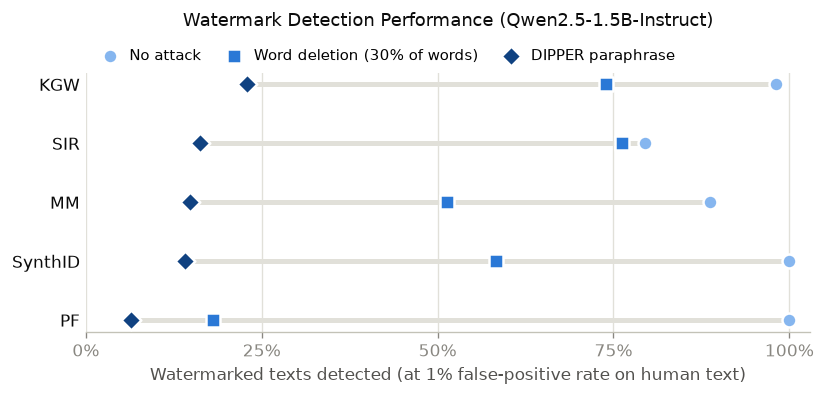

In [8]:
# Figure 1 for Qwen. Same code as above, with qwen_summary instead of summary.
order = qwen_summary.loc[PLOT_METHODS].sort_values("attacked_tpr_dipper").index
y_positions = np.arange(len(order))

fig, ax = plt.subplots(figsize=(7, 3.4))

for y, method in zip(y_positions, order):
    values = [qwen_summary.loc[method, col] * 100 for col, _, _, _ in conditions]
    ax.plot([min(values), max(values)], [y, y], color=GRID, linewidth=3, zorder=1)

for col, label, color, marker in conditions:
    ax.scatter(qwen_summary.loc[order, col] * 100, y_positions, s=70, color=color, marker=marker,
               edgecolor=SURFACE, linewidth=1.5, label=label, zorder=3)

ax.set_yticks(y_positions, [PLOT_NAMES.get(m, m) for m in order])
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlim(0, 103)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Watermarked texts detected (at 1% false-positive rate on human text)")

ax.set_title("Watermark Detection Performance (Qwen2.5-1.5B-Instruct)",
             fontsize=11, color=INK, pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9,
          handletextpad=0.3, columnspacing=1.2, borderaxespad=0.2)

fig.tight_layout()
# fig.savefig("fig_detection_under_attack_qwen.pdf", bbox_inches="tight")
plt.show()

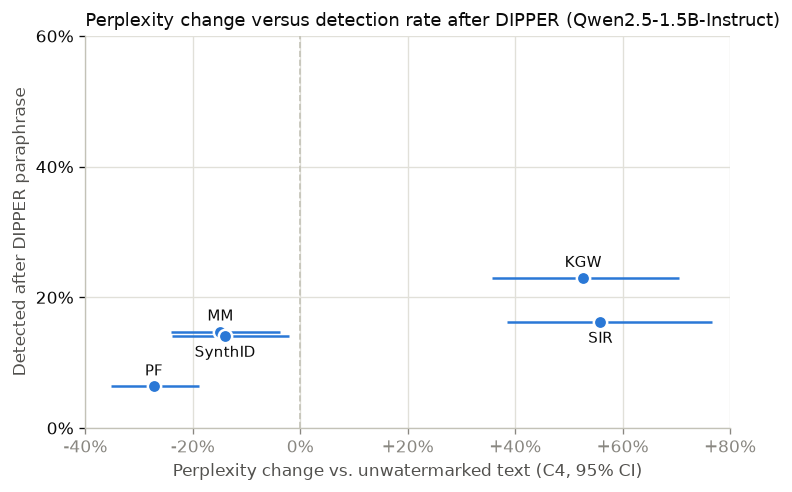

In [9]:
# Figure 2 for Qwen. Same code as above, with the Qwen data and a wider x-axis.
ppl_change = (np.exp(qwen_ppl_deltas.loc[PLOT_METHODS, "delta_vs_none"]) - 1) * 100
ppl_low = (np.exp(qwen_ppl_deltas.loc[PLOT_METHODS, "ci_low"]) - 1) * 100
ppl_high = (np.exp(qwen_ppl_deltas.loc[PLOT_METHODS, "ci_high"]) - 1) * 100
dipper = qwen_summary.loc[PLOT_METHODS, "attacked_tpr_dipper"] * 100

# MM and SynthID sit almost on the same spot, so one label goes above and one below.
label_offsets = {
    "KGW": (0, 9), "MorphMark": (0, 9), "PF": (0, 9),
    "SynthID": (0, -10), "SIR": (0, -10),
}

fig, ax = plt.subplots(figsize=(6.5, 4.2))

ax.axvline(0, color=AXIS, linewidth=1, linestyle="--", zorder=1)

ax.errorbar(ppl_change, dipper, xerr=[ppl_change - ppl_low, ppl_high - ppl_change],
            fmt="o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5,
            ecolor=BLUE, elinewidth=1.5, capsize=0, zorder=3)

for method in PLOT_METHODS:
    ax.annotate(PLOT_NAMES.get(method, method), (ppl_change[method], dipper[method]),
                xytext=label_offsets[method],
                textcoords="offset points", ha="center", va="center",
                fontsize=9, color=INK)

ax.set_xlim(-40, 80)
ax.set_ylim(0, 60)
ax.set_xticks([-40, -20, 0, 20, 40, 60, 80], ["-40%", "-20%", "0%", "+20%", "+40%", "+60%", "+80%"])
ax.set_yticks([0, 20, 40, 60], ["0%", "20%", "40%", "60%"])
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Perplexity change vs. unwatermarked text (C4, 95% CI)")
ax.set_ylabel("Detected after DIPPER paraphrase")
ax.set_title("Perplexity change versus detection rate after DIPPER (Qwen2.5-1.5B-Instruct)",
             loc="left", fontsize=11, color=INK)

fig.tight_layout()
# fig.savefig("fig_quality_vs_robustness_qwen.pdf", bbox_inches="tight")
plt.show()

### Qwen vs. OPT-1.3B: what changes

**Similar**
- Without attack, KGW, PF and SynthID are still caught 98–100% of the time.
- KGW and SIR are still the most robust *and* the most costly: both raise perplexity a lot (about +53% and +56% on Qwen, +37% and +48% on OPT).
- PF is still the weakest under attack, and its lower perplexity again comes with slightly more repetitive text.
- DIPPER still removes most watermarks. SynthID ends at 14% on both models.
- SIR is still about 2x slower to generate than the others.

**Different**
- **Detection is weaker overall on Qwen.** MorphMark (89%) and SIR (80%) miss more texts even without attack (OPT: 98–100%).
- **Word deletion hurts much more.** On OPT four methods kept 91–97%; on Qwen the best keep about 75% (SIR, KGW), MorphMark and SynthID drop to about 50–58%, and PF to 18%.
- **SIR loses its lead under DIPPER:** 51% on OPT, 16% on Qwen. KGW is now the most robust (23%).
- **MorphMark and SynthID now *lower* perplexity** by about 14–15% (OPT: no clear change).
- Likely reason for the weaker detection: shorter texts (about 120 vs. 180 scored tokens) and an instruction-tuned model that is more confident in its next word, which leaves less room to hide a signal. The attacks were not harsher on Qwen (similar similarity scores).

### Benchmark tasks on Qwen (change vs. unwatermarked)
- **GSM8K (math, accuracy 64.8% without watermark):** KGW −16% and SIR −19% (clear drop). PF −6%, SynthID +1% and MorphMark +5% are within noise.
- **Summarization (ROUGE-L):** KGW −7% and SIR −10% (clear drop). The others are within noise.
- **Translation (BLEU):** only SIR drops clearly (−9%). The others are within noise.
- **Overall:** SynthID and MorphMark cost nothing measurable on any task. KGW and SIR hurt reasoning and summarization; SIR also hurts translation.